# Credit Default Modeling
> Binary classification of Home Credit payment difficulty

The notebook loads the Home Credit application tables, encodes and scales the features, and compares logistic regression, random forests, and LightGBM. Performance is ROC AUC on an 80/20 train/validation split.


## 1. Overview

**Objective:** Predict whether an applicant will have payment difficulties (`TARGET` = 1) or repay without those difficulties (`TARGET` = 0). Each model outputs the probability of class 1.

**Data:** `application_train_aai.csv` (246,008 rows, 122 columns) and `application_test_aai.csv` (61,503 rows, 122 columns), plus `HomeCredit_columns_description.csv`. Columns cover demographics, income and credit amounts, employment, and housing. The positive class is 8.03% of training rows (19,751 of 246,008).

**Evaluation:** [ROC AUC](https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc) on predicted class-1 probabilities. `data_utils.get_train_val_sets()` holds out 20% of the training rows (`test_size=0.2`, `shuffle=True`, `random_state=42`). The test file is not scored.

1. Load the three source files with `data_utils.get_datasets()`.
2. Inspect shape, target balance, data types, cardinality, missingness, and a few feature distributions.
3. Split features and `TARGET` with `data_utils.get_feature_target()`, then split train and validation.
4. Run `preprocessing.preprocess_data()`: replace the `DAYS_EMPLOYED` sentinel `365243` with missing, ordinal-encode two-level categoricals, one-hot encode the rest, median-impute, and min-max scale.
5. Fit logistic regression, a default random forest, a tuned random forest, LightGBM, and two sklearn pipelines.
6. Compare train and validation ROC AUC, then write class-1 probabilities onto the test `TARGET` column.


In [ ]:
%matplotlib inline

# Import libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils.validation import check_is_fitted

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data_utils, preprocessing

## 2. Data

### 2.1 Sources

`data_utils.get_datasets()` downloads three files into `dataset/` when they are missing:

- `application_train_aai.csv` — labeled applications used for fitting and validation.
- `application_test_aai.csv` — applications whose `TARGET` column is later overwritten with predicted class-1 probabilities. No test ROC AUC is computed.
- `HomeCredit_columns_description.csv` — column definitions.

Download URLs are in `src/config.py`.


Load `app_train`, `app_test`, and `columns_description`, then check the expected shapes.


In [2]:
app_train, app_test, columns_description = data_utils.get_datasets()


if app_train.shape == (246008, 122):
    print("Success: app_train shape is correct!")
else:
    raise ValueError("Train dataset shape is incorrect, please review your code")

if isinstance(app_train, pd.DataFrame):
    print("Success: app_train type is correct!")
else:
    raise ValueError("Train dataset type is incorrect, please review your code")

if app_test.shape == (61503, 122):
    print("Success: app_test shape is correct!")
else:
    raise ValueError("Test dataset shape is incorrect, please review your code")

if isinstance(app_test, pd.DataFrame):
    print("Success: app_test type is correct!")
else:
    raise ValueError("Test dataset type is incorrect, please review your code")

Success: app_train shape is correct!
Success: app_train type is correct!
Success: app_test shape is correct!
Success: app_test type is correct!


### 2.2 Exploratory data analysis

The summaries below describe the training file before filtering or encoding.


#### Shape and columns


Row and column counts for the training and test sets.


In [4]:
# Print the shape of both datasets
print(f"Training dataset shape: {app_train.shape}")
print(f"Test dataset shape: {app_test.shape}")
print(f"\nNumber of samples in training set: {app_train.shape[0]:,}")
print(f"Number of samples in test set: {app_test.shape[0]:,}")
print(f"Number of features: {app_train.shape[1]}")

Training dataset shape: (246008, 122)
Test dataset shape: (61503, 122)

Number of samples in training set: 246,008
Number of samples in test set: 61,503
Number of features: 122


Column names in `app_train`.


In [5]:
print(f"Columns in the train dataset: {app_train.columns}")

Columns in the train dataset: Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='object', length=122)


First five training rows, transposed so features read as rows.


In [6]:
app_train.head().T  #.T transposes the data!

,0,1,2,3,4
SK_ID_CURR,428247,140966,407283,434300,446788
TARGET,0,0,0,0,0
NAME_CONTRACT_TYPE,Cash loans,Cash loans,Revolving loans,Cash loans,Cash loans
CODE_GENDER,F,M,F,F,F
FLAG_OWN_CAR,N,Y,N,N,N
...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,NaN,0.0,0.0,0.0,0.0
AMT_REQ_CREDIT_BUREAU_WEEK,NaN,0.0,0.0,0.0,0.0
AMT_REQ_CREDIT_BUREAU_MON,NaN,0.0,0.0,0.0,0.0
AMT_REQ_CREDIT_BUREAU_QRT,NaN,0.0,0.0,1.0,0.0


`TARGET` counts and share. Class 0 is 226,257 rows (91.97%); class 1 is 19,751 rows (8.03%).


Target Value Counts:
0    226257
1     19751
Name: TARGET, dtype: int64

Target Percentages:
0    91.971399
1     8.028601
Name: TARGET, dtype: float64


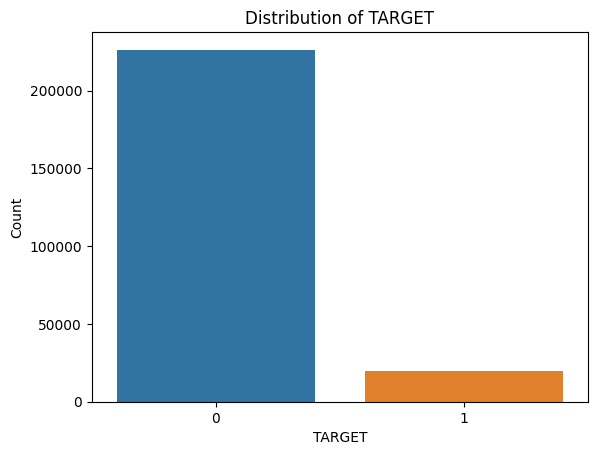

In [7]:
# Get value counts
target_counts = app_train['TARGET'].value_counts()
print("Target Value Counts:")
print(target_counts)

# Get percentages
target_percentages = app_train['TARGET'].value_counts(normalize=True) * 100
print("\nTarget Percentages:")
print(target_percentages)

# Target is categorical --> Using a bar chart to display distribution 
sns.countplot(data=app_train, x='TARGET')
plt.xlabel("TARGET")
plt.ylabel("Count")
plt.title("Distribution of TARGET")
plt.show()

Column counts by dtype: 65 `float64`, 41 `int64`, and 16 `object`.


In [8]:
print("Number of columns by data type:")
print(app_train.dtypes.value_counts())

Number of columns by data type:
float64    65
int64      41
object     16
dtype: int64


Distinct values in each object column. Four columns have two levels (`NAME_CONTRACT_TYPE`, `FLAG_OWN_CAR`, `FLAG_OWN_REALTY`, `EMERGENCYSTATE_MODE`) and are later ordinal-encoded. The rest are one-hot encoded. `ORGANIZATION_TYPE` has 58 levels.


In [9]:
cat_cols = app_train.select_dtypes(include='object').columns
app_train[cat_cols].nunique()

NAME_CONTRACT_TYPE             2
CODE_GENDER                    3
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
NAME_TYPE_SUITE                7
NAME_INCOME_TYPE               8
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
OCCUPATION_TYPE               18
WEEKDAY_APPR_PROCESS_START     7
ORGANIZATION_TYPE             58
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
WALLSMATERIAL_MODE             7
EMERGENCYSTATE_MODE            2
dtype: int64

Twenty columns with the highest share of missing values. `COMMONAREA_MEDI`, `COMMONAREA_AVG`, and `COMMONAREA_MODE` are each missing on 69.99% of rows (172,189).


In [10]:
# Count missing values per column
missing_counts = app_train.isnull().sum()

# Calculate percentages
missing_percentages = (app_train.isnull().sum() / len(app_train)) * 100

# Combine into a DataFrame
missing_data = pd.DataFrame({
    'Total': missing_counts,
    'Percent': missing_percentages
})

# Rounding percentages to match expected output 
missing_data['Percent'] = missing_data['Percent'].round(2)

# Filter only columns with missing data and sort by percentage descending
missing_data = missing_data[missing_data['Total'] > 0].sort_values('Percent', ascending=False)

# Printing top 20
print("Top 20 columns with missing data:")
print(missing_data.head(20))

Top 20 columns with missing data:
                           Total  Percent
COMMONAREA_MEDI           172189    69.99
COMMONAREA_AVG            172189    69.99
COMMONAREA_MODE           172189    69.99
NONLIVINGAPARTMENTS_MEDI  171096    69.55
NONLIVINGAPARTMENTS_MODE  171096    69.55
NONLIVINGAPARTMENTS_AVG   171096    69.55
FONDKAPREMONT_MODE        168561    68.52
LIVINGAPARTMENTS_MODE     168494    68.49
LIVINGAPARTMENTS_MEDI     168494    68.49
LIVINGAPARTMENTS_AVG      168494    68.49
FLOORSMIN_MODE            167255    67.99
FLOORSMIN_MEDI            167255    67.99
FLOORSMIN_AVG             167255    67.99
YEARS_BUILD_MODE          163980    66.66
YEARS_BUILD_MEDI          163980    66.66
YEARS_BUILD_AVG           163980    66.66
OWN_CAR_AGE               162503    66.06
LANDAREA_AVG              146436    59.52
LANDAREA_MEDI             146436    59.52
LANDAREA_MODE             146436    59.52


#### Feature distributions


Sample values and histogram of `AMT_CREDIT`.


In [11]:
# First seeing what kind of data we have in the AMT_CREDIT column
print("AMT_CREDIT First Five Rows:")
app_train["AMT_CREDIT"].head()

AMT_CREDIT First Five Rows:


0     634500.0
1    1223010.0
2     540000.0
3     439740.0
4     323388.0
Name: AMT_CREDIT, dtype: float64

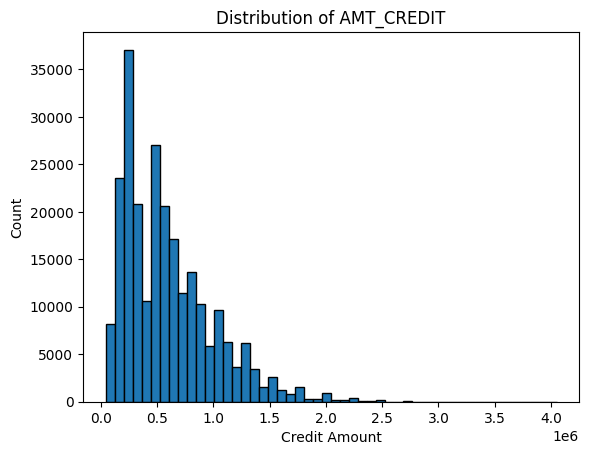

In [12]:
# Working with continous data, so we want continuous distribution! 
plt.hist(app_train['AMT_CREDIT'], bins=50, edgecolor='black')
plt.xlabel("Credit Amount")
plt.ylabel("Count")
plt.title("Distribution of AMT_CREDIT")
plt.show()

Counts and percentages for `NAME_EDUCATION_TYPE`. Secondary / secondary special is 174,657 rows (71.00%); higher education is 59,990 (24.39%).


In [13]:
# First seeing what kind of data we have in the NAME_EDUCATION_TYPE column
print("NAME_EDUCATION_TYPE First Five Rows:")
app_train["NAME_EDUCATION_TYPE"].head()

NAME_EDUCATION_TYPE First Five Rows:


0                 Higher education
1                 Higher education
2                 Higher education
3    Secondary / secondary special
4    Secondary / secondary special
Name: NAME_EDUCATION_TYPE, dtype: object

Education Level Counts:
Secondary / secondary special    174657
Higher education                  59990
Incomplete higher                  8248
Lower secondary                    2984
Academic degree                     129
Name: NAME_EDUCATION_TYPE, dtype: int64

Education Level Percentages:
Secondary / secondary special    70.996472
Higher education                 24.385386
Incomplete higher                 3.352736
Lower secondary                   1.212969
Academic degree                   0.052437
Name: NAME_EDUCATION_TYPE, dtype: float64


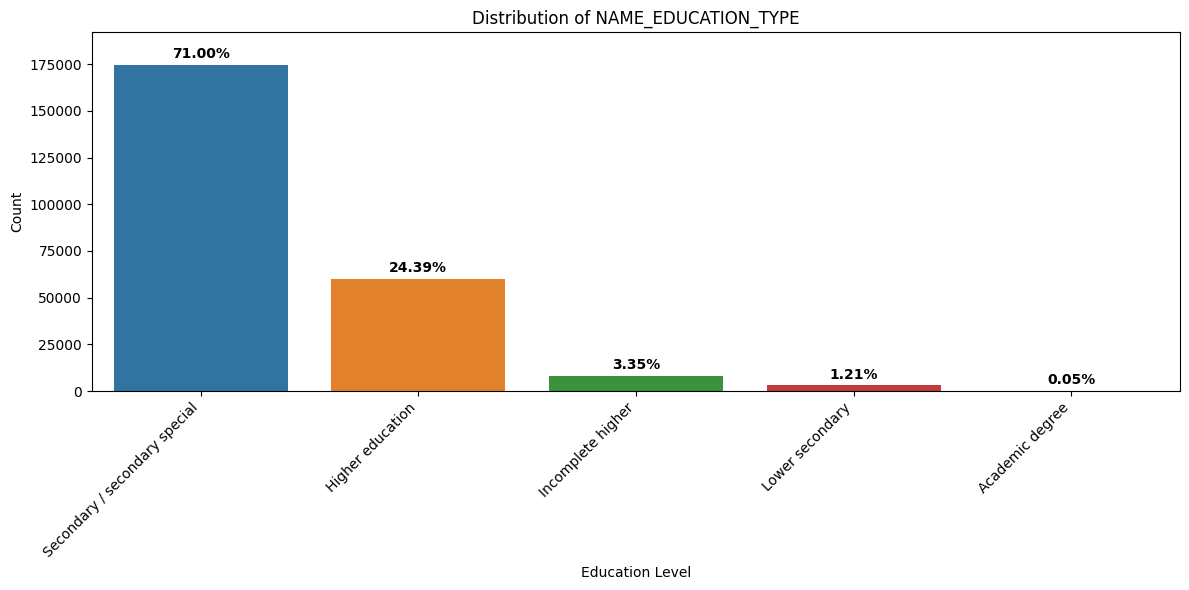

In [14]:
# Get value counts
education_counts = app_train['NAME_EDUCATION_TYPE'].value_counts()
print("Education Level Counts:")
print(education_counts)

# Get percentages
education_percentages = app_train['NAME_EDUCATION_TYPE'].value_counts(normalize=True) * 100
print("\nEducation Level Percentages:")
print(education_percentages)

# Target is categorical --> Using a bar chart to display distribution 
plt.figure(figsize=(12,6))
ax = sns.countplot(data=app_train, x='NAME_EDUCATION_TYPE', 
                   order=education_counts.index)  

# Extend y-axis to make room for labels on tall bars
y_max = max(education_counts) * 1.1  # Add 10% extra space
ax.set_ylim(0, y_max)

# Superposing pre-calculated percentages
for i, category in enumerate(education_counts.index):
    count = education_counts[category]
    percentage = education_percentages[category]
    ax.text(i, count + (y_max * 0.01), 
            f'{percentage:.2f}%', 
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xlabel("Education Level")
plt.ylabel("Count")
plt.title("Distribution of NAME_EDUCATION_TYPE")
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

Bar chart of `OCCUPATION_TYPE` (18 levels).


In [15]:
# First seeing what kind of data we have in the OCCUPATION_TYPE column
print("OCCUPATION_TYPE First Five Rows:")
app_train["OCCUPATION_TYPE"].head()

OCCUPATION_TYPE First Five Rows:


0               NaN
1        Core staff
2       Accountants
3    Cleaning staff
4          Managers
Name: OCCUPATION_TYPE, dtype: object

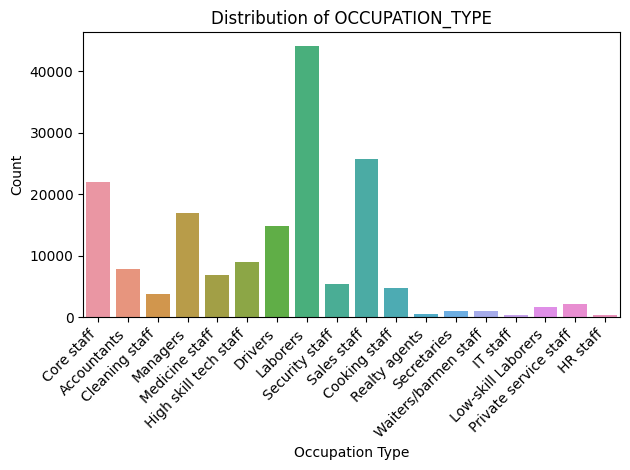

In [16]:
# OCCUPATION_TYPE is categorical --> Using a bar chart to display distribution 
sns.countplot(data=app_train, x='OCCUPATION_TYPE')
plt.xlabel("Occupation Type")
plt.ylabel("Count")
plt.title("Distribution of OCCUPATION_TYPE")
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

Bar chart of `NAME_FAMILY_STATUS`.


In [17]:
# First seeing what kind of data we have in the NAME_FAMILY_STATUS column
print("NAME_FAMILY_STATUS First Five Rows:")
app_train["NAME_FAMILY_STATUS"].head()

NAME_FAMILY_STATUS First Five Rows:


0                   Widow
1                 Married
2    Single / not married
3                 Married
4                 Married
Name: NAME_FAMILY_STATUS, dtype: object

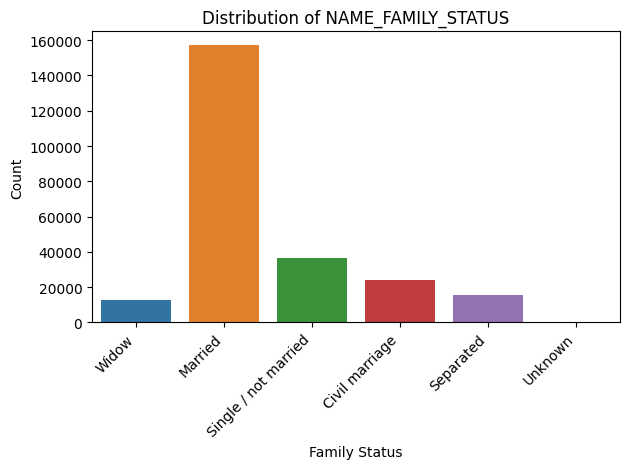

In [20]:
# NAME_FAMILY_STATUS is categorical --> Using a bar chart to display distribution 
sns.countplot(data=app_train, x='NAME_FAMILY_STATUS')
plt.xlabel("Family Status")
plt.ylabel("Count")
plt.title("Distribution of NAME_FAMILY_STATUS")
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

Counts of `NAME_INCOME_TYPE` split by `TARGET`.


In [19]:
# First seeing what kind of data we have in the NAME_INCOME_TYPE column
print("NAME_INCOME_TYPE First Five Rows:")
app_train["NAME_INCOME_TYPE"].head()

NAME_INCOME_TYPE First Five Rows:


0               Pensioner
1                 Working
2    Commercial associate
3                 Working
4                 Working
Name: NAME_INCOME_TYPE, dtype: object

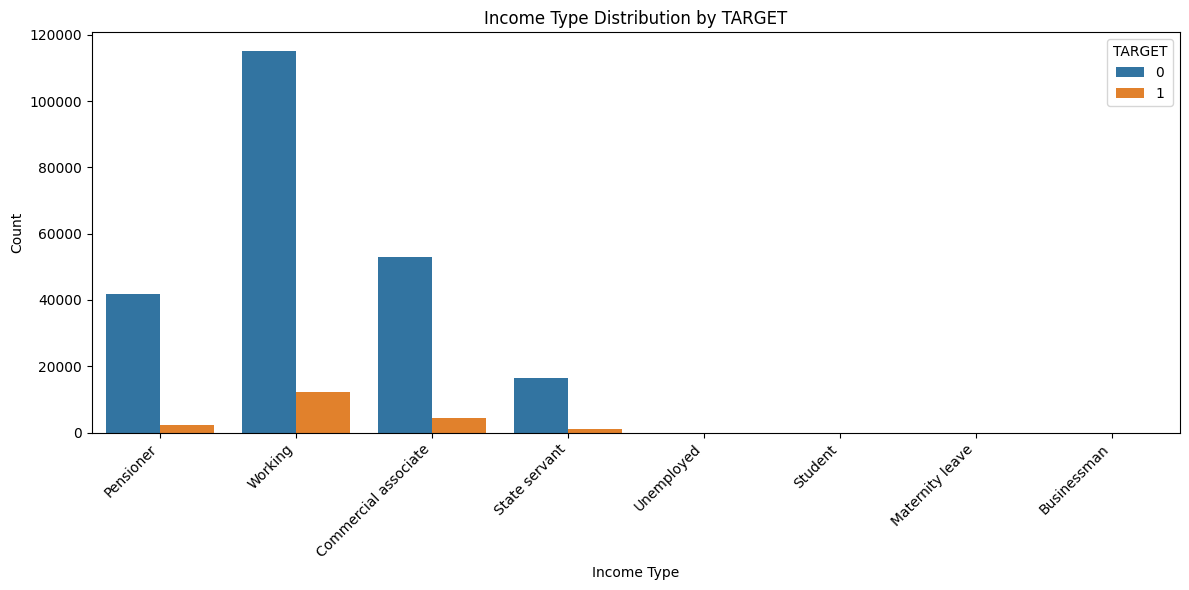

In [21]:
# Both NAME_INCOME_TYPE and TARGET are categorical 
plt.figure(figsize=(12, 6))
sns.countplot(data=app_train, x='NAME_INCOME_TYPE', hue='TARGET')
plt.title('Income Type Distribution by TARGET')
plt.xlabel('Income Type')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(title='TARGET', labels=['0', '1'])
plt.tight_layout()
plt.show()

## 3. Preprocessing


### 3.1 Features and target

`data_utils.get_feature_target()` drops `TARGET` from each frame. `X_train` and `X_test` keep the remaining 121 columns; `y_train` and `y_test` are the `TARGET` series.


In [4]:
# Now we execute the function above to get the result
X_train, y_train, X_test, y_test = data_utils.get_feature_target(app_train, app_test)


if X_train.shape == (246008, 121):
    print("Success: X_train shape is correct!")
else:
    raise ValueError("X_train dataset shape is incorrect, please review your code")

if isinstance(X_train, pd.DataFrame):
    print("Success: X_train type is correct!")
else:
    raise ValueError("Train dataset type is incorrect, please review your code")

if y_train.shape == (246008,) or y_train.shape == (246008, 1):
    print("Success: y_train shape is correct!")
else:
    raise ValueError("Train labels shape is incorrect, please review your code")

if X_test.shape == (61503, 121):
    print("Success: X_test shape is correct!")
else:
    raise ValueError("Test dataset shape is incorrect, please review your code")

if isinstance(X_test, pd.DataFrame):
    print("Success: X_test type is correct!")
else:
    raise ValueError("Test dataset type is incorrect, please review your code")

if y_test.shape == (61503,) or y_test.shape == (61503, 1):
    print("Success: y_test shape is correct!")
else:
    raise ValueError("Test labels shape is incorrect, please review your code")

Success: X_train shape is correct!
Success: X_train type is correct!
Success: y_train shape is correct!
Success: X_test shape is correct!
Success: X_test type is correct!
Success: y_test shape is correct!


### 3.2 Train/validation split

`data_utils.get_train_val_sets()` calls `train_test_split` with `test_size=0.2`, `shuffle=True`, and `random_state=42`. The split is not stratified. The fit set has 196,806 rows and the validation set has 49,202 rows.


In [5]:
# Now we execute the function above to get the result
X_train, X_val, y_train, y_val = data_utils.get_train_val_sets(X_train, y_train)


if X_train.shape == (196806, 121):
    print("Success: X_train shape is correct!")
else:
    raise ValueError("X_train dataset shape is incorrect, please review your code")

if isinstance(X_train, pd.DataFrame):
    print("Success: X_train type is correct!")
else:
    raise ValueError("Train dataset type is incorrect, please review your code")

if y_train.shape == (196806,) or y_train.shape == (196806, 1):
    print("Success: y_train shape is correct!")
else:
    raise ValueError("Train labels shape is incorrect, please review your code")

if X_val.shape == (49202, 121):
    print("Success: X_test shape is correct!")
else:
    raise ValueError("Test dataset shape is incorrect, please review your code")

if isinstance(X_val, pd.DataFrame):
    print("Success: X_test type is correct!")
else:
    raise ValueError("Test dataset type is incorrect, please review your code")

if y_val.shape == (49202,) or y_val.shape == (49202, 1):
    print("Success: y_test shape is correct!")
else:
    raise ValueError("Test labels shape is incorrect, please review your code")

Success: X_train shape is correct!
Success: X_train type is correct!
Success: y_train shape is correct!
Success: X_test shape is correct!
Success: X_test type is correct!
Success: y_test shape is correct!


### 3.3 Encoding and scaling

`preprocessing.preprocess_data()` copies the three feature frames and then:

1. Replaces `DAYS_EMPLOYED` value `365243` with missing.
2. Fits an `OrdinalEncoder` (`handle_unknown="use_encoded_value"`, `unknown_value=-1`) on columns with two training levels, and a `OneHotEncoder` (`sparse_output=False`, `handle_unknown="ignore"`) on the remaining object columns.
3. Median-imputes with `SimpleImputer` fit on the training rows.
4. Scales with `MinMaxScaler` fit on the training rows.

The returned arrays are `train_data`, `val_data`, and `test_data`. Fitting uses `train_data`, model comparison uses `val_data`, and `test_data` is reserved for the probability export. One-hot encoding expands 121 columns to 246.


In [6]:
train_data, val_data, test_data = preprocessing.preprocess_data(X_train, X_val, X_test)


if train_data.shape == (196806, 246):
    print("Success: train_data shape is correct!")
else:
    raise ValueError("train_data dataset shape is incorrect, please review your code")

if isinstance(train_data, np.ndarray):
    print("Success: train_data type is correct!")
else:
    raise ValueError("Train dataset type is incorrect, please review your code")

if val_data.shape == (49202, 246):
    print("Success: val_data shape is correct!")
else:
    raise ValueError("val_data dataset shape is incorrect, please review your code")

if isinstance(val_data, np.ndarray):
    print("Success: val_data type is correct!")
else:
    raise ValueError("Validation dataset type is incorrect, please review your code")

if test_data.shape == (61503, 246):
    print("Success: test_data shape is correct!")
else:
    raise ValueError("test_data dataset shape is incorrect, please review your code")

if isinstance(test_data, np.ndarray):
    print("Success: test_data type is correct!")
else:
    raise ValueError("Test dataset type is incorrect, please review your code")

Input train data shape:  (196806, 121)
Input val data shape:  (49202, 121)
Input test data shape:  (61503, 121) 



Success: train_data shape is correct!
Success: train_data type is correct!
Success: val_data shape is correct!
Success: val_data type is correct!
Success: test_data shape is correct!
Success: test_data type is correct!


## 4. Models


The same preprocessed matrices are used throughout. Models fit on `train_data` and are scored with `roc_auc_score` on class-1 probabilities for `train_data` and `val_data`. Cells that start with `%%time` record wall time.


### 4.1 Logistic regression


Fit `LogisticRegression(C=0.0001)` on `train_data` and `y_train`. No `class_weight` is set. The fitted estimator is `log_reg`.


In [23]:
%%time

# This is an example code on how to:
#   - Create and fit (train) a logistic regression
#   - Assign to `log_reg` variable
log_reg = None
log_reg = LogisticRegression(C=0.0001)
log_reg.fit(train_data, y_train)

CPU times: total: 18.3 s
Wall time: 27.3 s


LogisticRegression(C=0.0001)

Check that `log_reg` is a fitted `LogisticRegression`.


In [24]:
if isinstance(log_reg, LogisticRegression):
    print("Success: Logistic regression model type is correct!")
else:
    raise ValueError(
        "Logistic regression model type is incorrect, please review your code"
    )

check_is_fitted(log_reg)

Success: Logistic regression model type is correct!


`predict_proba` returns one column per class. ROC AUC uses column 1, the probability of payment difficulty. On the validation matrix that array has shape `(49202, 2)` before the column slice.


Class-1 probabilities from `log_reg` on `train_data` and `val_data`.


In [25]:
# Example code to show you how to use the Logistic Regression model
# to predict probabilities for each class and then, use the probabilities for the
# class 1 only.

# Train data predictions (class 1)
log_reg_train = log_reg.predict_proba(train_data)[:, 1]

# Validation data predictions (class 1)
log_reg_val = log_reg.predict_proba(val_data)[:, 1]

Train and validation ROC AUC for `log_reg`, via [`roc_auc_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html).


Print train and validation ROC AUC for `log_reg`.


In [26]:
# Example code to show you how to get the ROC AUC Score on train and val datasets

# Train ROC AUC Score
roc_auc_train = roc_auc_score(y_true=y_train, y_score=log_reg_train)
print(f"Train ROC AUC Score: {roc_auc_train:.4f}")

# Validation ROC AUC Score
roc_auc_val = roc_auc_score(y_true=y_val, y_score=log_reg_val)
print(f"Validation ROC AUC Score: {roc_auc_val:.4f}")

Train ROC AUC Score: 0.6798
Validation ROC AUC Score: 0.6772


#### Evaluation questions

Comparing the train and validation ROC AUC, does `log_reg` underfit, overfit, or neither?

**Performance target:** validation ROC AUC around 0.67.


Neither. Train ROC AUC is 0.6798 and validation ROC AUC is 0.6772, a gap of 0.0026. The validation score meets the 0.67 target.


Check that the validation ROC AUC is a float of at least 0.6.


In [27]:
if isinstance(roc_auc_val, float):
    print("Success: AUC ROC score type is correct!")
else:
    raise ValueError("AUC ROC score type is incorrect, please review your code")

if roc_auc_val >= 0.6:
    print("Success: AUC ROC score is correct!")
else:
    raise ValueError("AUC ROC score is incorrect, please review your code")

Success: AUC ROC score type is correct!
Success: AUC ROC score is correct!


**Logistic regression results.**

| Model | Train ROC AUC | Validation ROC AUC | Gap |
| --- | ---: | ---: | ---: |
| `LogisticRegression(C=0.0001)` | 0.6798 | 0.6772 | 0.0026 |

- Validation ROC AUC 0.6772 meets the 0.67 target.
- The gap is 0.0026. `C=0.0001`, wall time is 27.3 s, and `class_weight` is unset.


### 4.2 Random forest


A default `RandomForestClassifier` tests a higher-capacity model on the same matrices.


Fit `RandomForestClassifier(n_jobs=-1)`. No other hyperparameters are set, including `class_weight`.


In [28]:
%%time

# Training a Random Forest model
rf = RandomForestClassifier(n_jobs=-1)
rf.fit(train_data, y_train)

CPU times: total: 19min 30s
Wall time: 17min 34s


RandomForestClassifier(n_jobs=-1)

Check that `rf` is a fitted `RandomForestClassifier`.


In [29]:
if isinstance(rf, RandomForestClassifier):
    print("Success: RandomForestClassifier model type is correct!")
else:
    raise ValueError(
        "RandomForestClassifier model type is incorrect, please review your code"
    )

check_is_fitted(rf)

Success: RandomForestClassifier model type is correct!


Class-1 probabilities from `rf` on `train_data` and `val_data`.


In [30]:
# Train data predictions (class 1)
rf_pred_train = rf.predict_proba(train_data)[:, 1]

# Validation data predictions (class 1)
rf_pred_val = rf.predict_proba(val_data)[:, 1]

Train and validation ROC AUC for `rf`.


In [31]:
# Train ROC AUC Score
roc_auc_train = roc_auc_score(y_true=y_train, y_score=rf_pred_train)
print(f"Train ROC AUC Score: {roc_auc_train:.4f}")

# Validation ROC AUC Score
roc_auc_val = roc_auc_score(y_true=y_val, y_score=rf_pred_val)
print(f"Validation ROC AUC Score: {roc_auc_val:.4f}")

Train ROC AUC Score: 1.0000
Validation ROC AUC Score: 0.7064


#### Evaluation questions

Comparing train and validation ROC AUC, does the default random forest underfit, overfit, or neither?

**Performance target:** validation ROC AUC around 0.7.


Overfitting. Train ROC AUC is 1.0000 and validation ROC AUC is 0.7064, a gap of 0.2936. Wall time is 17 min 34 s. Only `n_jobs=-1` is set on the estimator.


**Random forest results.**

| Model | Train ROC AUC | Validation ROC AUC | Gap |
| --- | ---: | ---: | ---: |
| `LogisticRegression(C=0.0001)` | 0.6798 | 0.6772 | 0.0026 |
| `RandomForestClassifier(n_jobs=-1)` | 1.0000 | 0.7064 | 0.2936 |

- The forest reaches a perfect train score of 1.0000.
- Validation ROC AUC 0.7064 is near the 0.7 target and above the logistic regression score of 0.6772.
- The gap widens from 0.0026 to 0.2936.


### 4.3 Tuned random forest


`RandomizedSearchCV` draws 10 hyperparameter combinations and scores each with 3-fold cross-validation on `train_data` (`n_iter=10`, `cv=3`, `scoring="roc_auc"`, `random_state=42`). The search space is `n_estimators` in {10, 50, 100}, `max_depth` in {5, 10, 20, `None`}, `min_samples_split` in {2, 5, 10}, `min_samples_leaf` in {1, 2, 4}, and `max_features` in {`sqrt`, `log2`}. The base estimator is `RandomForestClassifier(n_jobs=-1, random_state=42)`.


Fit the random-forest search on `train_data` and `y_train`.


In [33]:
%%time

# Define the parameter grid to search
param_distributions = {
    'n_estimators': [10, 50, 100],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
}

# Create base model
rf_base = RandomForestClassifier(n_jobs=-1, random_state=42)

# Create RandomizedSearchCV
rf_random = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_distributions,
    n_iter=10,  # Trying 10 random combinations (adjust based on time)
    cv=3,       # 3-fold cross-validation
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=2   # Shows progress
)

# Fit the model - THIS WILL TAKE TIME!
rf_random.fit(train_data, y_train)

print(f"Best parameters: {rf_random.best_params_}")
print(f"Best CV score: {rf_random.best_score_:.4f}")


Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10}
Best CV score: 0.7271
CPU times: total: 4min
Wall time: 51min 24s


Class-1 probabilities from `rf_random` on `train_data` and `val_data`.


In [34]:
# Train data predictions (class 1)
rf_tuned_pred_train = rf_random.predict_proba(train_data)[:, 1]

# Validation data predictions (class 1)
rf_tuned_pred_val = rf_random.predict_proba(val_data)[:, 1]

Train and validation ROC AUC for the tuned forest.


In [35]:
# Train ROC AUC Score
roc_auc_train = roc_auc_score(y_train, rf_tuned_pred_train)
print(f"Train ROC AUC Score: {roc_auc_train:.4f}")

# Validation ROC AUC Score
roc_auc_val = roc_auc_score(y_val, rf_tuned_pred_val)
print(f"Validation ROC AUC Score: {roc_auc_val:.4f}")

Train ROC AUC Score: 0.8070
Validation ROC AUC Score: 0.7302


#### Evaluation questions

Comparing train and validation ROC AUC, does the tuned forest underfit, overfit, or neither?

**Performance target:** validation ROC AUC around 0.7 or higher.


Overfitting, with a smaller gap than the default forest. Train ROC AUC is 0.8070 and validation ROC AUC is 0.7302, a gap of 0.0768. The search reports a best cross-validation score of 0.7271 with `n_estimators=50`, `max_depth=10`, `min_samples_leaf=4`, `min_samples_split=2`, and `max_features="sqrt"`. Wall time is 51 min 24 s.


**Tuned random forest results.**

| Model | Train ROC AUC | Validation ROC AUC | Gap |
| --- | ---: | ---: | ---: |
| Random forest (default) | 1.0000 | 0.7064 | 0.2936 |
| Random forest (tuned) | 0.8070 | 0.7302 | 0.0768 |

- Validation ROC AUC rises from 0.7064 to 0.7302.
- The gap falls from 0.2936 to 0.0768.
- The tuned gap is still much larger than the logistic regression gap of 0.0026.


## 5. Test predictions

`rf_random` writes class-1 probabilities for `test_data` onto `app_test["TARGET"]` and saves them with `config.DATASET_TEST`. This step does not compute a test ROC AUC. A later cell overwrites the same column with probabilities from `lgbm_random`. The feature-selection pipeline does not write the file.

```python
test_preds = rf_random.predict_proba(test_data)[:, 1]
app_test["TARGET"] = test_preds
app_test.to_csv(config.DATASET_TEST, index=False)
```


In [36]:
%%time

# Test data predictions :D
test_preds = rf_random.predict_proba(test_data)[:, 1]
app_test["TARGET"] = test_preds
app_test.to_csv(config.DATASET_TEST, index=False)


CPU times: total: 44.2 s
Wall time: 1min 34s


## 6. Additional models


### 6.1 LightGBM


[LightGBM](https://lightgbm.readthedocs.io/en/latest/) is fit on the same matrices and compared with the forest. The environment already has LightGBM 4.6.0.


In [26]:
# First ensuring we have the necessary library installed
try:
    import lightgbm as lgb
    print(f"LightGBM version {lgb.__version__} is installed!")
except ImportError:
    print("LightGBM not installed. Installing now...")
    !pip install lightgbm
    import lightgbm as lgb
    print(f"LightGBM version {lgb.__version__} installed successfully!")

LightGBM version 4.6.0 is installed!


Create the base `LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)`. This cell does not fit the model. `class_weight` is unset, and no early-stopping callback is used.


In [28]:
%%time

from sklearn.model_selection import RandomizedSearchCV
import lightgbm as lgb

# Creating base LightGBM model
lgbm_base = lgb.LGBMClassifier(
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

CPU times: total: 0 ns
Wall time: 0 ns


Search `n_estimators` in {50, 100, 200}, `max_depth` in {5, 10, 15, -1}, `learning_rate` in {0.01, 0.05, 0.1}, `num_leaves` in {15, 31, 63}, `subsample` in {0.6, 0.8, 1.0}, `colsample_bytree` in {0.6, 0.8, 1.0}, and `min_child_samples` in {20, 50, 100}. The search uses `n_iter=10`, `cv=3`, `scoring="roc_auc"`, `n_jobs=-1`, and `random_state=42`.


In [29]:
# Using hyperparameter tuning to ensure best results!

# Parameter search space
lgbm_param_dist = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, -1],         
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [15, 31, 63],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_samples': [20, 50, 100],   
}
# Creating RandomizedSearchCV 
lgbm_random = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=lgbm_param_dist,
    n_iter=10,             
    cv=3,                  
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

# Fit the model 
print("Training LightGBM model...")
lgbm_random.fit(train_data, y_train)

# Show best parameters found
print(f"Best parameters: {lgbm_random.best_params_}")
print(f"Best CV score: {lgbm_random.best_score_:.4f}")

Training LightGBM model...
Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'subsample': 0.6, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best CV score: 0.7536


Class-1 probabilities from `lgbm_random` on `train_data` and `val_data`.


In [30]:
# Train data predictions (class 1)
lgbm_tuned_pred_train = lgbm_random.predict_proba(train_data)[:, 1]

# Validation data predictions (class 1)
lgbm_tuned_pred_val = lgbm_random.predict_proba(val_data)[:, 1]

Train and validation ROC AUC for `lgbm_random`.


In [31]:
# Train ROC AUC Score
roc_auc_train = roc_auc_score(y_train, lgbm_tuned_pred_train)
print(f"Train ROC AUC Score: {roc_auc_train:.4f}")

# Validation ROC AUC Score
roc_auc_val = roc_auc_score(y_val, lgbm_tuned_pred_val)
print(f"Validation ROC AUC Score: {roc_auc_val:.4f}")

Train ROC AUC Score: 0.7956
Validation ROC AUC Score: 0.7531


Overwrite `app_test["TARGET"]` with class-1 probabilities from `lgbm_random` and save `config.DATASET_TEST`.


In [32]:
# Test data predictions :D
test_preds = lgbm_random.predict_proba(test_data)[:, 1]
app_test["TARGET"] = test_preds
app_test.to_csv(config.DATASET_TEST, index=False)

**LightGBM results.**

| Model | Train ROC AUC | Validation ROC AUC | Gap |
| --- | ---: | ---: | ---: |
| Random forest (tuned) | 0.8070 | 0.7302 | 0.0768 |
| LightGBM (`lgbm_random`) | 0.7956 | 0.7531 | 0.0425 |

Best parameters: `n_estimators=200`, `max_depth=5`, `learning_rate=0.1`, `num_leaves=15`, `min_child_samples=20`, `subsample=0.6`, `colsample_bytree=0.8`. Best cross-validation score: 0.7536.

- Validation ROC AUC is higher than the tuned forest (0.7531 versus 0.7302).
- The train-validation gap is smaller (0.0425 versus 0.0768).
- No wall time is printed for this search.


### 6.2 Logistic regression pipeline


A sklearn [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) chains `VarianceThreshold` and `LogisticRegression` on the preprocessed matrices.


In [7]:
# First importing the necessary libraries and tools
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

The inputs are already scaled. The pipeline is `VarianceThreshold()` (default threshold 0.0) and `LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)`.


In [14]:
# Using Logistic Regression over KNN 
# --> KNN not great with unbalanced dataset & high dimensionality 
# --> our metrics: 
# ----> 92% class 0, 8% class 1, 246 features
pipe = Pipeline([
    ('selector', VarianceThreshold()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',  # handles imbalanced dataset!
        random_state=42
    ))
])

pipe.fit(train_data, y_train)

Pipeline(steps=[('selector', VarianceThreshold()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

Class-1 probabilities from `pipe` on `train_data` and `val_data`.


In [ ]:
# Train data predictions (class 1)
pipe_train_preds = pipe.predict_proba(train_data)[:, 1]

# Validation data predictions (class 1)
pipe_val_preds = pipe.predict_proba(val_data)[:, 1]

Train and validation ROC AUC for `pipe`.


In [16]:
# Train ROC AUC Score
roc_auc_train = roc_auc_score(y_train, pipe_train_preds)
print(f"Train ROC AUC Score: {roc_auc_train:.4f}")

# Validation ROC AUC Score
roc_auc_val = roc_auc_score(y_val, pipe_val_preds)
print(f"Validation ROC AUC Score: {roc_auc_val:.4f}")

Train ROC AUC Score: 0.7503
Validation ROC AUC Score: 0.7470


**Pipeline results.**

| Model | Train ROC AUC | Validation ROC AUC | Gap |
| --- | ---: | ---: | ---: |
| `LogisticRegression(C=0.0001)` | 0.6798 | 0.6772 | 0.0026 |
| `Pipeline` (`VarianceThreshold`, balanced logistic regression) | 0.7503 | 0.7470 | 0.0033 |

- The gap of 0.0033 is close to the baseline gap of 0.0026 and much smaller than either forest.
- Validation ROC AUC 0.7470 is above the baseline 0.6772 and below tuned LightGBM 0.7531.
- This is the logistic regression that sets `class_weight="balanced"`.


### 6.3 Feature selection and LightGBM pipeline

`VarianceThreshold` and `SelectKBest` run inside a pipeline with LightGBM. `preprocessing` and `data_utils` stay unchanged. The standalone selector cell below has no stored output; the search fits its own selectors.


**Feature selection.** The executed pipeline uses `VarianceThreshold(threshold=0.01)` and `SelectKBest(f_classif)`. The search chooses `k`.


In [ ]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif

Define a fixed `SelectKBest(f_classif, k=100)` after `VarianceThreshold(threshold=0.01)`. This cell has no stored output.


In [ ]:
# Remove low-variance features 
var_selector = VarianceThreshold(threshold=0.01)  # Remove if variance < 0.01
train_reduced = var_selector.fit_transform(train_data)
val_reduced = var_selector.transform(val_data)
test_reduced = var_selector.transform(test_data)

# Compound with top k statistical feature selection 
k_best = SelectKBest(f_classif, k=100)  # Keep top 100 features
train_selected = k_best.fit_transform(train_reduced, y_train)
val_selected = k_best.transform(val_reduced)
test_selected = k_best.transform(test_reduced)



**LightGBM pipeline.** The fitted pipeline is `VarianceThreshold(threshold=0.01)`, `SelectKBest(f_classif)`, and `LGBMClassifier(random_state=42, n_jobs=-1, class_weight="balanced", verbose=-1)`. `RandomizedSearchCV` uses `n_iter=15`, `cv=3`, `scoring="roc_auc"`, and `random_state=42`. The search includes `kbest__k` in {50, 75, 100}.


In [27]:
%%time

# Create a pipeline with LightGBM
lgbm_pipeline = Pipeline([
    ('variance', VarianceThreshold(threshold=0.01)),
    ('kbest', SelectKBest(f_classif)),
    ('classifier', lgb.LGBMClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight='balanced',  # still need to handle the imbalance!
        verbose=-1
    ))
])

# Define parameter grid
param_grid = {
    'kbest__k': [50, 75, 100],  
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [8, 10, 12],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__num_leaves': [31, 63],
    'classifier__subsample': [0.7, 0.8],
    'classifier__colsample_bytree': [0.7, 0.8],
    'classifier__min_child_samples': [20, 50],
}

# RandomizedSearchCV for tuning
best_model = RandomizedSearchCV(
    lgbm_pipeline,
    param_distributions=param_grid,
    n_iter=15,  
    cv=3,
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

best_model.fit(train_data, y_train)

print(f"\n Best parameters found:")
for param, value in best_model.best_params_.items():
    print(f"  {param}: {value}")

Fitting 3 folds for each of 15 candidates, totalling 45 fits



 Best parameters found:
  kbest__k: 75
  classifier__subsample: 0.8
  classifier__num_leaves: 31
  classifier__n_estimators: 200
  classifier__min_child_samples: 20
  classifier__max_depth: 12
  classifier__learning_rate: 0.05
  classifier__colsample_bytree: 0.8
CPU times: total: 2min 25s
Wall time: 40min 4s


Class-1 probabilities from `best_model` on `train_data` and `val_data`.


In [33]:
# Train data predictions (class 1)
best_model_train_preds = best_model.predict_proba(train_data)[:, 1]

# Validation data predictions (class 1)
best_model_val_preds = best_model.predict_proba(val_data)[:, 1]

Train and validation ROC AUC for `best_model`.


In [32]:
# Train ROC AUC Score
roc_auc_train = roc_auc_score(y_train, best_model_train_preds)
print(f"Train ROC AUC Score: {roc_auc_train:.4f}")

# Validation ROC AUC Score
roc_auc_val = roc_auc_score(y_val, best_model_val_preds)
print(f"Validation ROC AUC Score: {roc_auc_val:.4f}")

Train ROC AUC Score: 0.7910
Validation ROC AUC Score: 0.7493


**LightGBM pipeline results.**

| Model | Train ROC AUC | Validation ROC AUC | Gap |
| --- | ---: | ---: | ---: |
| LightGBM (`lgbm_random`) | 0.7956 | 0.7531 | 0.0425 |
| LightGBM pipeline (`best_model`) | 0.7910 | 0.7493 | 0.0417 |

Selected settings: `k=75`, `n_estimators=200`, `max_depth=12`, `learning_rate=0.05`, `num_leaves=31`, `min_child_samples=20`, `subsample=0.8`, `colsample_bytree=0.8`. Wall time is 40 min 4 s. No best cross-validation score is printed. `class_weight="balanced"` is set.

- Validation ROC AUC is 0.0038 below `lgbm_random` (0.7493 versus 0.7531).
- The gap, 0.0417, is almost the same as `lgbm_random`'s 0.0425.
- These probabilities are not written to `application_test_aai.csv`.


**Summary.**

The highest validation ROC AUC is 0.7531, from `lgbm_random` (LightGBM tuned with `RandomizedSearchCV`, no `class_weight`).

| Model | Train ROC AUC | Validation ROC AUC | Gap |
| --- | ---: | ---: | ---: |
| Logistic regression (`C=0.0001`) | 0.6798 | 0.6772 | 0.0026 |
| Random forest (default) | 1.0000 | 0.7064 | 0.2936 |
| Random forest (tuned) | 0.8070 | 0.7302 | 0.0768 |
| LightGBM (`lgbm_random`) | 0.7956 | 0.7531 | 0.0425 |
| Logistic pipeline (`class_weight="balanced"`) | 0.7503 | 0.7470 | 0.0033 |
| LightGBM pipeline (`class_weight="balanced"`) | 0.7910 | 0.7493 | 0.0417 |

- The default forest memorizes the training set (train 1.0000, validation 0.7064).
- Tuning the forest raises validation ROC AUC to 0.7302 and cuts the gap to 0.0768. The model still overfits.
- The balanced logistic pipeline reaches validation ROC AUC 0.7470 with a gap of 0.0033.
- Variance filtering, `SelectKBest`, and `class_weight="balanced"` on LightGBM reach 0.7493 and do not beat `lgbm_random`.

**Recommendation:** Use `lgbm_random` for test probabilities. It has the highest validation ROC AUC in the notebook, and the LightGBM section already writes those probabilities to `config.DATASET_TEST`. No model uses early stopping.
